In [67]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder     
from sklearn.metrics import mean_absolute_error
from scipy.special import expit,softmax # expit : 이진분류함수 , softmax : 다중분류 0-1 숫자로 변환




In [68]:
# LogisticRegression 이진분류 -> 다중분류
fish = pd.read_csv('data/fish_logistic.csv')


In [69]:
fish['Species'].unique() # 7개 종류 : 'Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt'

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [70]:
#데이터 전처리
data = fish[fish.columns[1:]].values
label = fish['Species'].values


In [71]:
#데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [72]:
# LogisticRegression - 정규화작업 해야함

ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [73]:
# # 다중분류
# # C(대문자표기) - alpha,C 규제 : C가 높아지면 완화, 낮아지면 강화
# # alpha for문 그래프로 가장 최적화된 규제를 찾아서 적용
# # max_iter 반복을 자동화해주는 매개변수
# train_score = []
# test_score = []
# lr = LogisticRegression(C=20,max_iter=1000)
# lr.fit(train_scaled,train_label)
# print()


In [76]:
# 다중분류
# C(대문자표기) - alpha,C 규제 : C가 높아지면 완화, 낮아지면 강화
# alpha for문 그래프로 가장 최적화된 규제를 찾아서 적용
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc :
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))
print()

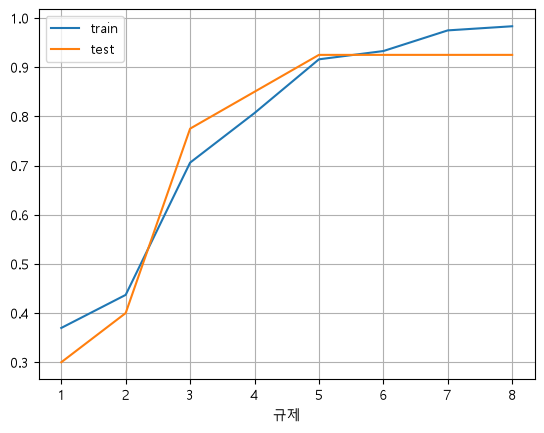

In [82]:
#C의 규제 선 그래프
list = [1,2,3,4,5,6,7,8]
plt.plot(list,train_score)
plt.plot(list,test_score)
plt.grid()
plt.legend(['train','test'])
plt.xlabel('규제순서')
plt.xlabel('규제')
plt.show()

In [ ]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [ ]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
soft1 = softmax(decisions,axis=1) #axis = 1 : 행방향 / axis = 0 : 열방향
soft1
np.round(soft1,decimals=3)

array([[0.   , 0.014, 0.842, 0.   , 0.135, 0.007, 0.003],
       [0.   , 0.003, 0.044, 0.   , 0.007, 0.946, 0.   ],
       [0.   , 0.   , 0.034, 0.934, 0.015, 0.016, 0.   ],
       [0.011, 0.034, 0.305, 0.006, 0.567, 0.   , 0.076],
       [0.   , 0.   , 0.904, 0.002, 0.089, 0.002, 0.001]])

In [ ]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  0.9327731092436975
test정확도 :  0.925


In [ ]:
fish[:2]

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [ ]:

train_data[:5]

array([[720.    ,  35.    ,  40.6   ,  16.3618,   6.09  ],
       [500.    ,  45.    ,  48.    ,   6.96  ,   4.896 ],
       [  7.5   ,  10.5   ,  11.6   ,   1.972 ,   1.16  ],
       [110.    ,  22.    ,  23.5   ,   5.5225,   3.995 ],
       [140.    ,  20.7   ,  23.2   ,   8.5376,   3.2944]])

In [ ]:
#무게, 길이, 대각선 , 높이 , 넓이를 입력받아
# 242.0,25.4,30.0,11.52,4.02
# 290.0,26.3,31.2,12.48,4.3056
# 분류생선과 확률을 출력하시오
# 분류생선은 93.1% 확률로 bream 판별됩니다.
in_data = input('무게 길이 대각선 높이 넓이를 입력하세요.').split(',')
in_data2 = list(map(float,in_data))
indata_scaled = ss.transform([in_data2])
# lr.predict_proba(indata_scaled)
decisions = lr.decision_function(indata_scaled)
soft1 = softmax(decisions,axis=1) #axis = 1 : 행방향 / axis = 0 : 열방향
soft1

result = lr.predict(indata_scaled)
result2 = lr.predict_proba(indata_scaled)
# result3 = np.round(soft1,decimals=3)
if result[0] =='Bream' :
    result3 = result2[0][0]
elif result[0] =='Parkki' :
    result3 = result2[0][1]
elif result[0] =='Perch' :
    result3 = result2[0][2]
elif result[0] =='Pike' :
    result3 = result2[0][3]
elif result[0] =='Roach' :
    result3 = result2[0][4]
elif result[0] =='Smelt' :
    result3 = result2[0][5]
else:
    result3 = result2[0][6]
result3
print(f'분류생선은 {result3*100:.2f}% 확률로  / {result[0]}로 판별됩니다. ')

분류생선은 92.03% 확률로  / Pike로 판별됩니다. 


In [ ]:
# np.round(soft1,decimals=3)
result3

array([[0.   , 0.957, 0.003, 0.   , 0.038, 0.001, 0.001]])